# FitNets KD Student — CNN1D Teacher (Keras -> PyTorch)

Notebook train **1 student** bằng **FitNets** (Romero et al., ICLR 2015) — huấn luyện 2 giai đoạn,
pipeline **y hệt `fitnets-kd-dnn.ipynb`**, chỉ thay kiến trúc DNN → CNN1D.

- **Teacher:** CNN1D [128,128,256] (train & lưu bằng Keras `best_model_cnn1d_128_128_256.keras`).
  Notebook load Keras, **tự convert trọng số sang PyTorch**, sanity-check argmax khớp 100%.
- **Student:** MiniCNN [32,32,64] (chia đều /4 filters, giữ nguyên độ sâu & cấu trúc block).
- **lr / batch_size:** từ Optuna teacher CNN (`0.00005` / `512`).
- **Hyperparameter FitNets giữ NGUYÊN** như bản DNN (HINT_EPOCHS=50, KD_EPOCHS=50, λ 4→1, τ=3).
- **Hint layer:** feature map sau block 2 (giữa). Teacher `9×128`, student `9×32` (cùng length=9).
  **Regressor = Conv1D 1×1** (32→128 channels, giữ length) — chuẩn FitNets cho CNN.

Lưu `.pth` (state_dict), model size `count_params()×4/1024²`, plots giống hệt bản DNN.


## Cell 1 — Cấu hình & Import

In [1]:
!pip install -q pyarrow pandas scikit-learn torch tensorflow matplotlib seaborn

import os, gc, time, glob, warnings, json, tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (
    classification_report, roc_auc_score,
    accuracy_score, confusion_matrix, f1_score
)

warnings.filterwarnings('ignore')

# ── Duong dan ────────────────────────────────────────────────────────────────
INPUT_DIR    = '/kaggle/input/datasets/rsnngo/37ft-thang3737'
TEACHER_DIR  = '/kaggle/input/datasets/rsnngo/teacher-model-thang3737'
TEACHER_KERAS_PATH = f'{TEACHER_DIR}/best_model_cnn1d_128_128_256.keras'   # INPUT: CNN Keras
TEACHER_PTH_CACHE  = '/kaggle/working/teacher_cnn_converted.pth'           # cache PyTorch

OUTPUT_DIR   = '/kaggle/working/'
TRAIN_FILE   = os.path.join(INPUT_DIR, 'train_standard_p3.2.parquet')
VAL_FILE     = os.path.join(INPUT_DIR, 'val_standard_p3.2.parquet')
TEST_FILE    = os.path.join(INPUT_DIR, 'test_standard_p3.2.parquet')
CLASS_WEIGHTS_JSON = os.path.join(INPUT_DIR, 'class_weights_p3.2.json')

FITNET_PATH     = os.path.join(OUTPUT_DIR, 'student_cnn_fitnets_classw3_37ft.pth')
FITNET_CKPT_DIR = os.path.join(OUTPUT_DIR, 'ckpt_fitnets_cnn')
for d in [OUTPUT_DIR, FITNET_CKPT_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Hang so model ─────────────────────────────────────────────────────────────
NUM_FEATURES = 37
NUM_CLASSES  = 8
LABEL_COL    = 'label'
FILTERS_TEACHER = [128, 128, 256]   # CNN1D teacher
FILTERS_STUDENT = [32, 32, 64]      # MiniCNN -- chia deu /4, giu nguyen do sau
KERNEL_SIZE  = 3
DROPOUT_RATE = 0.1
LABEL_NAMES = {0:'Benign',1:'DDoS',2:'DoS',3:'BruteForce',
               4:'Spoofing',5:'Recon',6:'Web-Based',7:'Mirai'}
CLASS_NAMES = [LABEL_NAMES[i] for i in range(NUM_CLASSES)]
COLORS = ['#4C9BE8','#E84C4C','#F5A623','#9B59B6',
          '#2ECC71','#1ABC9C','#8B4513','#607D8B']

# ── Hyperparameters training (lr & batch tu Optuna teacher CNN) ──────────────
BATCH_SIZE       = 512        # tu cnn1d-v2.ipynb
LR               = 0.00005    # tu cnn1d-v2.ipynb
WEIGHT_DECAY     = 0.0         # CNN: Adam, KHONG weight decay
CLASS_WEIGHT_MAX = 3.0       # giu nguyen nhu ban FitNets DNN
CHECKPOINT_EVERY = 5
RANDOM_SEED      = 42

# ── FitNets hyperparams (GIU NGUYEN y het ban DNN) ───────────────────────────
HINT_EPOCHS  = 50
KD_EPOCHS    = 50
N_EPOCHS     = HINT_EPOCHS + KD_EPOCHS   # 100

# Hint = feature map sau block 2 (giua). Teacher 9x128, student 9x32 (cung length=9).
# Regressor Conv1D 1x1: 32 -> 128 channels, giu length.
HINT_BLOCK   = 2       # lay feature map sau block thu 2 (1-indexed)
HINT_CH      = 128     # channels teacher tai block 2
GUIDED_CH    = 32      # channels student tai block 2
# Length feature map sau conv cuoi (37 -> pool/2 x3 = 4). Dung de reindex flatten khi convert.
FLAT_LEN     = NUM_FEATURES // (2 ** len(FILTERS_TEACHER))   # 37 // 8 = 4

# KD (Eq. 2): lambda giam tuyen tinh 4 -> 1, tau = 3 (GIU NGUYEN nhu ban DNN)
LAMBDA_INIT  = 4.0
LAMBDA_FINAL = 1.0
TAU          = 3.0

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('=' * 62)
print('  FitNets KD Student -- CNN1D Teacher (Keras->PyTorch, 2-stage)')
print('=' * 62)
print(f'  Device       : {DEVICE}')
print(f'  Batch size   : {BATCH_SIZE}   LR: {LR}   WD: {WEIGHT_DECAY}')
print(f'  Tong epoch   : {N_EPOCHS}  (hint {HINT_EPOCHS} + KD {KD_EPOCHS})')
print(f'  Hint block   : {HINT_BLOCK} (teacher {HINT_CH}ch <- student {GUIDED_CH}ch)')
print(f'  Regressor    : Conv1D 1x1 ({GUIDED_CH} -> {HINT_CH} channels)')
print(f'  KD           : lambda {LAMBDA_INIT} -> {LAMBDA_FINAL} (linear), tau = {TAU}')
print('  Scheduler    : KHONG dung (LR co dinh), luu best epoch theo val loss')
print('=' * 62)


  FitNets KD Student -- CNN1D Teacher (Keras->PyTorch, 2-stage)
  Device       : cuda
  Batch size   : 512   LR: 5e-05   WD: 0.0
  Tong epoch   : 100  (hint 50 + KD 50)
  Hint block   : 2 (teacher 128ch <- student 32ch)
  Regressor    : Conv1D 1x1 (32 -> 128 channels)
  KD           : lambda 4.0 -> 1.0 (linear), tau = 3.0
  Scheduler    : KHONG dung (LR co dinh), luu best epoch theo val loss


## Load class weights (`weights_balanced`, clip max=3)

In [2]:
def load_class_weights(json_path, num_classes=NUM_CLASSES, clip_max=CLASS_WEIGHT_MAX):
    """Doc class_weights_p3.json, lay 'weights_balanced', clip max."""
    with open(json_path, 'r') as f:
        raw = json.load(f)
    weights = np.ones(num_classes, dtype=np.float32)
    if isinstance(raw, dict) and any(k in raw for k in ('weights_balanced','class_weights','weights')):
        for key in ('weights_balanced','class_weights','weights'):
            if key in raw:
                arr = raw[key]
                assert len(arr) == num_classes, f'{key} len {len(arr)} != {num_classes}'
                weights = np.array(arr, dtype=np.float32)
                print(f'  Lay class weight tu key "{key}"')
                break
    elif isinstance(raw, list):
        assert len(raw) == num_classes
        weights = np.array(raw, dtype=np.float32)
    elif isinstance(raw, dict):
        name_to_idx = {v: k for k, v in LABEL_NAMES.items()}
        for k, val in raw.items():
            idx = int(k) if str(k).isdigit() else name_to_idx[k]
            weights[idx] = float(val)
    weights_clipped = np.minimum(weights, clip_max)
    return torch.tensor(weights_clipped, dtype=torch.float32, device=DEVICE), weights

try:
    class_weights, class_weights_raw = load_class_weights(CLASS_WEIGHTS_JSON)
    print(f'Class weights (balanced -> clip max={CLASS_WEIGHT_MAX:.1f}):')
    for i in range(NUM_CLASSES):
        clip = ' <- CLIP' if class_weights_raw[i] > CLASS_WEIGHT_MAX else ''
        print(f'  [{i}] {LABEL_NAMES[i]:12s}: {class_weights_raw[i]:8.4f} -> {class_weights[i].item():.4f}{clip}')
except FileNotFoundError:
    print(f'CANH BAO: khong thay {CLASS_WEIGHTS_JSON} -> class_weights=None')
    class_weights = None


  Lay class weight tu key "weights_balanced"
Class weights (balanced -> clip max=3.0):
  [0] Benign      :   0.8334 -> 0.8334
  [1] DDoS        :   0.2914 -> 0.2914
  [2] DoS         :   0.9012 -> 0.9012
  [3] BruteForce  :  69.7046 -> 3.0000 <- CLIP
  [4] Spoofing    :   2.0023 -> 2.0023
  [5] Recon       :   1.4567 -> 1.4567
  [6] Web-Based   :  36.8116 -> 3.0000 <- CLIP
  [7] Mirai       :   0.9697 -> 0.9697


## Cell 2 — Dataset (reshape cho CNN1D: (samples, 37, 1))

In [3]:
class ParquetDataset(Dataset):
    """Load parquet, reshape X thanh (N, 1, 37) cho Conv1d PyTorch (channels-first)."""
    def __init__(self, path, label_col=LABEL_COL):
        df = pd.read_parquet(path)
        feat_cols = [c for c in df.columns if c != label_col]
        assert len(feat_cols) == NUM_FEATURES, \
            f'Feature mismatch: {len(feat_cols)} != {NUM_FEATURES}'
        X = df[feat_cols].to_numpy(dtype=np.float32)
        # PyTorch Conv1d input: (N, channels=1, length=37)
        self.X = torch.from_numpy(X).unsqueeze(1)          # (N, 1, 37)
        self.y = torch.from_numpy(df[label_col].to_numpy(dtype=np.int64))
        print(f'  {path.split("/")[-1]}: {len(self.X):,} mau, shape {tuple(self.X.shape[1:])}')
    def __len__(self):        return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

print('Dang doc du lieu ...')
train_ds = ParquetDataset(TRAIN_FILE)
val_ds   = ParquetDataset(VAL_FILE)
test_ds  = ParquetDataset(TEST_FILE)

kw = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=True)
train_loader = DataLoader(train_ds, shuffle=True,  **kw)
val_loader   = DataLoader(val_ds,   shuffle=False, **kw)
test_loader  = DataLoader(test_ds,  shuffle=False, **kw)
print(f'Dataset san sang | train {len(train_loader):,} batches')


Dang doc du lieu ...
  train_standard_p3.2.parquet: 4,468,344 mau, shape (1, 37)
  val_standard_p3.2.parquet: 1,117,087 mau, shape (1, 37)
  test_standard_p3.2.parquet: 1,396,358 mau, shape (1, 37)
Dataset san sang | train 8,728 batches


## Cell 3 — Kiến trúc Teacher & Student (FitNets CNN)

- Teacher `CNN1DWithHint`: mỗi block `Conv1d→ReLU→MaxPool→BN→Dropout` (khớp Keras: Conv có activation='relu' fuse trước, rồi Pool→BN→Dropout).
- `forward_hint` trả (logits, hint) với hint = feature map sau block `HINT_BLOCK` (9×128).
- Student `MiniCNNWithGuided` [32,32,64] cùng cấu trúc, guided = feature map sau block 2 (9×32).
- Regressor = **Conv1d 1×1** (32→128 ch, giữ length=9).


In [4]:
# ── Teacher CNN1D [128,128,256], thu tu Conv->ReLU->Pool->BN->Dropout (khop Keras) ──
# Keras: Conv1D(f, activation='relu') -> MaxPool -> BN -> Dropout
#   => Conv+ReLU fuse truoc, roi Pool, roi BN, roi Dropout.
class CNN1DWithHint(nn.Module):
    def __init__(self, in_ch=1, filters=FILTERS_TEACHER, num_classes=NUM_CLASSES,
                 kernel=KERNEL_SIZE, dropout=DROPOUT_RATE, in_len=NUM_FEATURES):
        super().__init__()
        self.blocks = nn.ModuleList()
        ch = in_ch
        L = in_len
        for f in filters:
            block = nn.Sequential(
                nn.Conv1d(ch, f, kernel_size=kernel, padding='same'),
                nn.ReLU(),
                nn.MaxPool1d(kernel_size=2),
                nn.BatchNorm1d(f, eps=1e-3),
                nn.Dropout(dropout),
            )
            self.blocks.append(block)
            ch = f
            L = L // 2
        self.flat_dim = L * ch
        self.head = nn.Linear(self.flat_dim, num_classes)

    def forward(self, x):
        for block in self.blocks:
            x = block(x)
        x = x.flatten(1)
        return self.head(x)   # logits

    def forward_hint(self, x, hint_block=HINT_BLOCK):
        """Tra (logits, hint) -- hint = feature map sau block thu hint_block (1-indexed)."""
        hint = None
        for bi, block in enumerate(self.blocks, start=1):
            x = block(x)
            if bi == hint_block:
                hint = x                 # [B, HINT_CH, L_block]
        logits = self.head(x.flatten(1))
        return logits, hint


# ── Student MiniCNN [32,32,64] ───────────────────────────────────────────────
class MiniCNNWithGuided(nn.Module):
    def __init__(self, in_ch=1, filters=FILTERS_STUDENT, num_classes=NUM_CLASSES,
                 kernel=KERNEL_SIZE, dropout=DROPOUT_RATE, in_len=NUM_FEATURES):
        super().__init__()
        self.blocks = nn.ModuleList()
        ch = in_ch
        L = in_len
        for f in filters:
            block = nn.Sequential(
                nn.Conv1d(ch, f, kernel_size=kernel, padding='same'),
                nn.ReLU(),
                nn.MaxPool1d(kernel_size=2),
                nn.BatchNorm1d(f, eps=1e-3),
                nn.Dropout(dropout),
            )
            self.blocks.append(block)
            ch = f
            L = L // 2
        self.flat_dim = L * ch
        self.head = nn.Linear(self.flat_dim, num_classes)

    def forward(self, x):
        for block in self.blocks:
            x = block(x)
        return self.head(x.flatten(1))   # logits

    def forward_guided(self, x, guided_block=HINT_BLOCK):
        guided = None
        for bi, block in enumerate(self.blocks, start=1):
            x = block(x)
            if bi == guided_block:
                guided = x               # [B, GUIDED_CH, L_block]
        logits = self.head(x.flatten(1))
        return logits, guided


class FitNetStudent(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = MiniCNNWithGuided()
    def forward(self, x):
        return self.model(x)
    def forward_guided(self, x):
        return self.model.forward_guided(x)


# ── Regressor (Eq. 3): Conv1d 1x1, guided (32ch) -> hint (128ch), giu length ──
class Regressor(nn.Module):
    def __init__(self, in_ch=GUIDED_CH, out_ch=HINT_CH):
        super().__init__()
        self.conv = nn.Conv1d(in_ch, out_ch, kernel_size=1)   # 1x1 conv khop channels
        self.act  = nn.ReLU()   # hint teacher la output sau ReLU/Pool/BN -> khop non-linearity
    def forward(self, x):
        return self.act(self.conv(x))


def count_params(m): return sum(p.numel() for p in m.parameters())

print(f'Student params (FitNetStudent) : {count_params(FitNetStudent()):,}')


Student params (FitNetStudent) : 11,752


## Cell 4 — Loss Functions (giữ nguyên y hệt bản DNN)

In [5]:
def hint_loss(hint_teacher, guided_student, regressor):
    """Eq. (3): L_HT = 1/2 * || u_h(x) - r(v_g(x)) ||^2  (MSE tren feature map)."""
    pred = regressor(guided_student)    # [B, HINT_CH, L]
    return 0.5 * F.mse_loss(pred, hint_teacher, reduction='mean')


def kd_loss(logits_s, logits_t, labels, lam, tau=TAU):
    """Eq. (2): CE(y, P_S) + lambda * tau^2 * KL(P_T^tau || P_S^tau)."""
    p_t     = F.softmax(logits_t / tau, dim=-1)
    log_p_s = F.log_softmax(logits_s / tau, dim=-1)
    L_soft  = F.kl_div(log_p_s, p_t, reduction='batchmean') * (tau ** 2)
    L_ce    = F.cross_entropy(logits_s, labels, weight=class_weights)  # class weight vao CE
    return L_ce + lam * L_soft


def lambda_at(epoch_in_kd, total_kd=KD_EPOCHS, lam0=LAMBDA_INIT, lam1=LAMBDA_FINAL):
    if total_kd <= 1:
        return lam1
    frac = epoch_in_kd / (total_kd - 1)
    return lam0 + (lam1 - lam0) * frac

print('Loss functions san sang')
print(f'  hint_loss : 1/2 * MSE(hint_teacher, regressor(guided_student))  [Conv1d 1x1]')
print(f'  kd_loss   : CE + lambda * tau^2 * KL,  tau = {TAU}')
print(f'  lambda    : {LAMBDA_INIT} -> {LAMBDA_FINAL} tuyen tinh trong {KD_EPOCHS} epoch KD')


Loss functions san sang
  hint_loss : 1/2 * MSE(hint_teacher, regressor(guided_student))  [Conv1d 1x1]
  kd_loss   : CE + lambda * tau^2 * KL,  tau = 3.0
  lambda    : 4.0 -> 1.0 tuyen tinh trong 50 epoch KD


## Cell 5 — Load Teacher (Keras → PyTorch, frozen)

In [6]:
import tensorflow as tf

def load_teacher_from_keras(keras_path, cache_path=None):
    """Load Keras CNN1D (Conv(relu)->Pool->BN->Dropout x3 -> Flatten -> Dense softmax),
    build lai PyTorch (Conv->ReLU->Pool->BN->Dropout, output linear), copy trong so.
    LUU Y: Keras Conv1D kernel shape (kernel, in_ch, out_ch); PyTorch Conv1d (out_ch, in_ch, kernel)
    -> can transpose (2,1,0). Dense sau Flatten: Keras (in,out) -> PyTorch (out,in). BN eps=1e-3."""
    keras_model = tf.keras.models.load_model(keras_path)
    torch_model = CNN1DWithHint()

    keras_weighted = [l for l in keras_model.layers if l.get_weights()]
    # thu tu PyTorch: (Conv,BN) x3 trong cac block, roi head Dense
    torch_layers = []
    for block in torch_model.blocks:
        for m in block:
            if isinstance(m, (nn.Conv1d, nn.BatchNorm1d)):
                torch_layers.append(m)
    torch_layers.append(torch_model.head)

    assert len(keras_weighted) == len(torch_layers), (
        f'So layer co trong so khong khop: Keras={len(keras_weighted)}, PyTorch={len(torch_layers)}. '
        'Kiem tra FILTERS_TEACHER co dung [128,128,256].'
    )

    for k_layer, t_layer in zip(keras_weighted, torch_layers):
        wts = k_layer.get_weights()
        if isinstance(t_layer, nn.Conv1d):
            W, b = wts                                  # Keras Conv1D: (kernel, in_ch, out_ch)
            W_t = np.transpose(W, (2, 1, 0))            # -> PyTorch (out_ch, in_ch, kernel)
            t_layer.weight.data = torch.from_numpy(W_t.copy()).float()
            t_layer.bias.data   = torch.from_numpy(b).float()
        elif isinstance(t_layer, nn.BatchNorm1d):
            gamma, beta, mean, var = wts
            t_layer.weight.data       = torch.from_numpy(gamma).float()
            t_layer.bias.data         = torch.from_numpy(beta).float()
            t_layer.running_mean.data = torch.from_numpy(mean).float()
            t_layer.running_var.data  = torch.from_numpy(var).float()
        elif isinstance(t_layer, nn.Linear):
            # Keras Dense: (flat_dim, out). flat_dim cua Keras sap theo (LENGTH, CHANNELS)
            # (channels-last), con PyTorch flatten(1) sap theo (CHANNELS, LENGTH) (channels-first)
            # -> phai REINDEX hang cua W truoc khi transpose, neu khong Dense/head anh xa sai cot.
            W, b = wts                                  # (flat_dim, out)
            flat_dim = W.shape[0]
            C = t_layer.in_features // FLAT_LEN         # so channels tai conv cuoi
            L = FLAT_LEN                                 # length tai conv cuoi
            assert C * L == flat_dim, f'flat mismatch: C={C} L={L} flat={flat_dim}'
            # perm[p_pytorch] = k_keras, voi p=c*L+l (pytorch), k=l*C+c (keras)
            perm = np.zeros(flat_dim, dtype=np.int64)
            for c_ in range(C):
                for l_ in range(L):
                    perm[c_ * L + l_] = l_ * C + c_
            W_reordered = W[perm, :]                     # (flat_dim, out) dung thu tu PyTorch
            t_layer.weight.data = torch.from_numpy(W_reordered.T.copy()).float()  # (out, flat)
            t_layer.bias.data   = torch.from_numpy(b).float()

    torch_model.eval()
    if cache_path:
        torch.save(torch_model.state_dict(), cache_path)
        print(f'  Da cache PyTorch checkpoint -> {cache_path}')
    return torch_model, keras_model


print('Load & convert teacher CNN tu Keras sang PyTorch ...')
t_model, _keras_teacher = load_teacher_from_keras(TEACHER_KERAS_PATH, cache_path=TEACHER_PTH_CACHE)
t_model.to(DEVICE).eval()
for p in t_model.parameters(): p.requires_grad = False

t_params = count_params(t_model)
print(f'Teacher loaded | Params: {t_params:,} | Frozen: True | flat_dim={t_model.flat_dim}')

@torch.no_grad()
def teacher_forward(x):
    """Tra (logits_t, hint_t) -- hint la feature map [B, HINT_CH, L] sau block giua."""
    return t_model.forward_hint(x)

# ── Sanity check: Keras CNN dung input (N, 37, 1) channels-last; PyTorch (N, 1, 37) ──
_x_np    = train_ds.X[:256].numpy()               # (256, 1, 37) channels-first
_x_keras = np.transpose(_x_np, (0, 2, 1))         # -> (256, 37, 1) channels-last cho Keras
_x_torch = train_ds.X[:256].to(DEVICE)

_keras_pred = np.argmax(_keras_teacher.predict(_x_keras, verbose=0), axis=1)
_lt, _ht    = teacher_forward(_x_torch)
_torch_pred = _lt.argmax(dim=1).cpu().numpy()

assert np.array_equal(_keras_pred, _torch_pred), (
    'CONVERT LOI: PyTorch teacher KHONG khop Keras teacher! Kiem tra transpose kernel / thu tu layer.'
)
print(f'Sanity check: Keras vs PyTorch teacher argmax khop 100% ({len(_keras_pred)} mau)')
print(f'Teacher sanity: logits {tuple(_lt.shape)}, hint {tuple(_ht.shape)} (ky vong hint [B, {HINT_CH}, 9])')
assert _ht.shape[1] == HINT_CH
del _x_np, _x_keras, _x_torch, _keras_pred, _lt, _ht, _torch_pred
gc.collect()


Load & convert teacher CNN tu Keras sang PyTorch ...


I0000 00:00:1785772668.332264      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13754 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1785772668.334460      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


  Da cache PyTorch checkpoint -> /kaggle/working/teacher_cnn_converted.pth
Teacher loaded | Params: 157,576 | Frozen: True | flat_dim=1024


I0000 00:00:1785772671.603795      83 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Sanity check: Keras vs PyTorch teacher argmax khop 100% (256 mau)
Teacher sanity: logits (256, 8), hint (256, 128, 9) (ky vong hint [B, 128, 9])


300

## Cell 6 — Khởi tạo Student, Regressor & Optimizer

In [7]:
def find_latest_ckpt(ckpt_dir):
    files = sorted(glob.glob(os.path.join(ckpt_dir, 'ckpt_fitnet_epoch_*.pth')))
    return files[-1] if files else None

student   = FitNetStudent().to(DEVICE)
regressor = Regressor().to(DEVICE)

opt_hint = optim.Adam(list(student.parameters()) + list(regressor.parameters()),
                       lr=LR)
opt_kd   = optim.Adam(student.parameters(), lr=LR)

start_epoch   = 1
hint_losses, hint_val_losses = [], []      # FIX #2: theo doi hint val loss
train_losses, val_losses = [], []
best_hint_val     = float('inf')           # FIX #2: hint val loss thap nhat
best_guided_state = None                    # FIX #2: state student tai best hint val
best_val_loss = float('inf')
best_state    = None

latest = find_latest_ckpt(FITNET_CKPT_DIR)
if latest:
    ck = torch.load(latest, map_location='cpu')
    student.load_state_dict(ck['model_state']); student.to(DEVICE)
    if ck.get('regressor_state') is not None:
        regressor.load_state_dict(ck['regressor_state']); regressor.to(DEVICE)
    start_epoch   = ck['epoch'] + 1
    hint_losses     = ck.get('hint_losses',     [])
    hint_val_losses = ck.get('hint_val_losses', [])
    train_losses    = ck.get('train_losses',    [])
    val_losses      = ck.get('val_losses',      [])
    best_val_loss     = ck.get('best_val_loss',     float('inf'))
    best_hint_val     = ck.get('best_hint_val',     float('inf'))
    best_state        = {k: v.clone() for k, v in student.state_dict().items()}
    best_guided_state = ck.get('best_guided_state', None)
    print(f'  Resume: {os.path.basename(latest)} (tiep epoch {start_epoch})')
else:
    print('  Train tu dau')

print(f'Student params   : {count_params(student):,}')
print(f'Regressor params : {count_params(regressor):,} (chi dung o giai doan 1)')
print(f'Teacher params   : {t_params:,}')
print(f'Compression      : {1 - count_params(student)/t_params:.1%}')


  Train tu dau
Student params   : 11,752
Regressor params : 4,224 (chi dung o giai doan 1)
Teacher params   : 157,576
Compression      : 92.5%


## Cell 7 — Training Loop 2 giai đoạn (FitNets)

- Epoch `1 .. HINT_EPOCHS`: tối thiểu `hint_loss` (Eq. 3) trên feature map block giữa.
- Epoch `HINT_EPOCHS+1 .. N_EPOCHS`: tối thiểu `kd_loss` (Eq. 2), lambda giảm tuyến tính.


In [8]:
def save_ckpt(epoch):
    path = os.path.join(FITNET_CKPT_DIR, f'ckpt_fitnet_epoch_{epoch:04d}.pth')
    torch.save({
        'epoch'            : epoch,
        'model_state'      : (best_state if best_state is not None
                              else {k: v.cpu().clone() for k, v in student.state_dict().items()}),
        'regressor_state'  : {k: v.cpu().clone() for k, v in regressor.state_dict().items()},
        'hint_losses'      : hint_losses,
        'hint_val_losses'  : hint_val_losses,
        'train_losses'     : train_losses,
        'val_losses'       : val_losses,
        'best_val_loss'    : best_val_loss,
        'best_hint_val'    : best_hint_val,
        'best_guided_state': best_guided_state,
    }, path)
    return path


if start_epoch > N_EPOCHS:
    print('Da train xong. Load best state.')
    if best_state is not None:
        student.load_state_dict(best_state); student.to(DEVICE)
else:
    t_model.eval()
    print(f'[FitNets] Train tu epoch {start_epoch}/{N_EPOCHS} '
          f'(hint 1..{HINT_EPOCHS}, KD {HINT_EPOCHS+1}..{N_EPOCHS})')
    print(f'{"Epoch":>6} | {"Stage":>5} | {"TrainLoss":>10} | {"ValLoss":>10} | {"lambda":>7} | {"LR":>9}')
    print('-' * 66)
    t0 = time.time()

    for epoch in range(start_epoch, N_EPOCHS + 1):
        is_hint = (epoch <= HINT_EPOCHS)

        student.train(); regressor.train()
        run, n_seen = 0.0, 0
        lam = 0.0

        if is_hint:
            for Xb, yb in train_loader:
                Xb = Xb.to(DEVICE)
                _, hint_t   = teacher_forward(Xb)
                _, guided_s = student.forward_guided(Xb)
                loss = hint_loss(hint_t, guided_s, regressor)
                opt_hint.zero_grad(); loss.backward(); opt_hint.step()
                run += loss.item() * len(Xb); n_seen += len(Xb)
        else:
            lam = lambda_at(epoch - HINT_EPOCHS - 1)
            for Xb, yb in train_loader:
                Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
                logits_t, _ = teacher_forward(Xb)
                logits_s    = student(Xb)
                loss = kd_loss(logits_s, logits_t, yb, lam)
                opt_kd.zero_grad(); loss.backward(); opt_kd.step()
                run += loss.item() * len(yb); n_seen += len(yb)

        tr = run / max(n_seen, 1)
        if is_hint: hint_losses.append(tr)
        else:       train_losses.append(tr)

        student.eval(); regressor.eval()
        vrun, v_seen = 0.0, 0
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
                if is_hint:
                    _, hint_t   = teacher_forward(Xb)
                    _, guided_s = student.forward_guided(Xb)
                    vloss = hint_loss(hint_t, guided_s, regressor)
                    vrun += vloss.item() * len(Xb); v_seen += len(Xb)
                else:
                    logits_t, _ = teacher_forward(Xb)
                    logits_s    = student(Xb)
                    vloss = kd_loss(logits_s, logits_t, yb, lam)
                    vrun += vloss.item() * len(yb); v_seen += len(yb)
        vl = vrun / max(v_seen, 1)

        cur_lr = (opt_hint if is_hint else opt_kd).param_groups[0]['lr']

        flag = ''
        if is_hint:
            hint_val_losses.append(vl)
            # ── FIX #2: luu best_guided theo hint val loss (paper A.1.2: dung stage-1 theo val) ──
            if vl < best_hint_val:
                best_hint_val = vl
                best_guided_state = {k: v.cpu().clone() for k, v in student.state_dict().items()}
                flag = ' BEST-H'
            # Cuoi stage 1: nap lai best_guided truoc khi vao KD
            if epoch == HINT_EPOCHS and best_guided_state is not None:
                student.load_state_dict(best_guided_state); student.to(DEVICE)
                print(f'  -> Nap best_guided_state (hint val={best_hint_val:.4f}) truoc khi vao KD')
        else:
            val_losses.append(vl)
            if vl < best_val_loss:
                best_val_loss = vl
                best_state    = {k: v.cpu().clone() for k, v in student.state_dict().items()}
                flag = ' BEST'

        print(f'[{epoch:3d}/{N_EPOCHS}] | {"HINT" if is_hint else "KD":>5} | '
              f'{tr:10.4f} | {vl:9.4f}{flag:7s} | {lam:7.3f} | {cur_lr:.2e}')

        if epoch % CHECKPOINT_EVERY == 0 or epoch == N_EPOCHS:
            p = save_ckpt(epoch)
            print(f'  [CKPT] {os.path.basename(p)}')
        gc.collect()

    elapsed = time.time() - t0
    if best_state is not None:
        student.load_state_dict(best_state); student.to(DEVICE)
    torch.save(student.state_dict(), FITNET_PATH)
    print(f'\\nTrain xong: {elapsed/60:.1f} phut')
    print(f'Best hint val loss: {best_hint_val:.4f} (da nap truoc KD)')
    print(f'Best KD val loss  : {best_val_loss:.4f} -> {FITNET_PATH}')


[FitNets] Train tu epoch 1/100 (hint 1..50, KD 51..100)
 Epoch | Stage |  TrainLoss |    ValLoss |  lambda |        LR
------------------------------------------------------------------
[  1/100] |  HINT |     0.2520 |    0.1669 BEST-H |   0.000 | 5.00e-05
[  2/100] |  HINT |     0.1812 |    0.1467 BEST-H |   0.000 | 5.00e-05
[  3/100] |  HINT |     0.1728 |    0.1410 BEST-H |   0.000 | 5.00e-05
[  4/100] |  HINT |     0.1693 |    0.1388 BEST-H |   0.000 | 5.00e-05
[  5/100] |  HINT |     0.1674 |    0.1397        |   0.000 | 5.00e-05
  [CKPT] ckpt_fitnet_epoch_0005.pth
[  6/100] |  HINT |     0.1663 |    0.1356 BEST-H |   0.000 | 5.00e-05
[  7/100] |  HINT |     0.1655 |    0.1465        |   0.000 | 5.00e-05
[  8/100] |  HINT |     0.1651 |    0.1355 BEST-H |   0.000 | 5.00e-05
[  9/100] |  HINT |     0.1644 |    0.1341 BEST-H |   0.000 | 5.00e-05
[ 10/100] |  HINT |     0.1641 |    0.1341 BEST-H |   0.000 | 5.00e-05
  [CKPT] ckpt_fitnet_epoch_0010.pth
[ 11/100] |  HINT |     0.1638 |

## Cell 8 — Evaluate trên Test Set

In [9]:
def evaluate(student, label):
    student.eval()
    all_preds, all_probs, all_labels = [], [], []
    latencies = []

    with torch.no_grad():
        _ = student(test_ds.X[:BATCH_SIZE].to(DEVICE))
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

    tracemalloc.start(); gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.reset_peak_memory_stats()

    with torch.no_grad():
        for Xb, yb in test_loader:
            Xb = Xb.to(DEVICE)
            t0 = time.perf_counter()
            out = student(Xb)
            t1 = time.perf_counter()
            latencies.append((t1 - t0) / len(Xb))
            logits = out[0] if isinstance(out, tuple) else out
            all_probs.append(F.softmax(logits, dim=1).cpu())
            all_preds.append(logits.argmax(dim=1).cpu())
            all_labels.append(yb)

    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    _, ram_peak = tracemalloc.get_traced_memory(); tracemalloc.stop()

    preds  = torch.cat(all_preds).numpy()
    probs  = torch.cat(all_probs).numpy()
    labels = torch.cat(all_labels).numpy()

    acc       = accuracy_score(labels, preds)
    macro_auc = roc_auc_score(labels, probs, multi_class='ovr', average='macro')
    report    = classification_report(labels, preds, target_names=CLASS_NAMES, digits=4)
    n_params  = count_params(student)
    size_mb   = n_params * 4 / 1024**2
    inf_us    = np.mean(latencies) * 1e6
    inf_std   = np.std(latencies)  * 1e6
    ram_mb    = ram_peak / 1024**2
    vram_mb   = (torch.cuda.max_memory_allocated()/1024**2 if DEVICE.type=='cuda' else 0)

    result = (
        f"\n{'='*62}\n"
        f"  {label} -- TEST\n"
        f"{'='*62}\n"
        f"{report}\n"
        f"Accuracy         : {acc:.6f}\n"
        f"Macro AUC        : {macro_auc:.6f}\n"
        f"{'-'*62}\n"
        f"Model size       : {size_mb:.4f} MB  ({size_mb*1024:.2f} KB)\n"
        f"Params (student) : {n_params:,}\n"
        f"Params (teacher) : {t_params:,}\n"
        f"Compression      : {1 - n_params/t_params:.1%}\n"
        f"{'-'*62}\n"
        f"Inference/sample : {inf_us:.2f} +/- {inf_std:.2f} us\n"
        f"RAM peak         : {ram_mb:.2f} MB\n"
        f"VRAM peak        : {vram_mb:.2f} MB\n"
        f"{'='*62}\n"
    )
    print(result)
    with open(os.path.join(OUTPUT_DIR, 'results_fitnets_cnn.txt'), 'w') as f:
        f.write(result)
    return preds, probs, labels, acc, macro_auc

preds, probs, labels, acc, macro_auc = evaluate(student, 'FitNets Student (CNN Teacher)')



  FitNets Student (CNN Teacher) -- TEST
              precision    recall  f1-score   support

      Benign     0.7816    0.8379    0.8088    209448
        DDoS     0.9098    0.8476    0.8776    598978
         DoS     0.6130    0.7398    0.6705    193688
  BruteForce     0.8218    0.2137    0.3391      2504
    Spoofing     0.8194    0.7454    0.7807     87173
       Recon     0.7142    0.7193    0.7167    119826
   Web-Based     0.5457    0.0378    0.0706      4741
       Mirai     0.9987    0.9935    0.9961    180000

    accuracy                         0.8287   1396358
   macro avg     0.7755    0.6419    0.6575   1396358
weighted avg     0.8370    0.8287    0.8302   1396358

Accuracy         : 0.828724
Macro AUC        : 0.972852
--------------------------------------------------------------
Model size       : 0.0448 MB  (45.91 KB)
Params (student) : 11,752
Params (teacher) : 157,576
Compression      : 92.5%
--------------------------------------------------------------
Inferen

## Cell 9 — Plots (loss 2 giai đoạn, confusion matrix, F1)

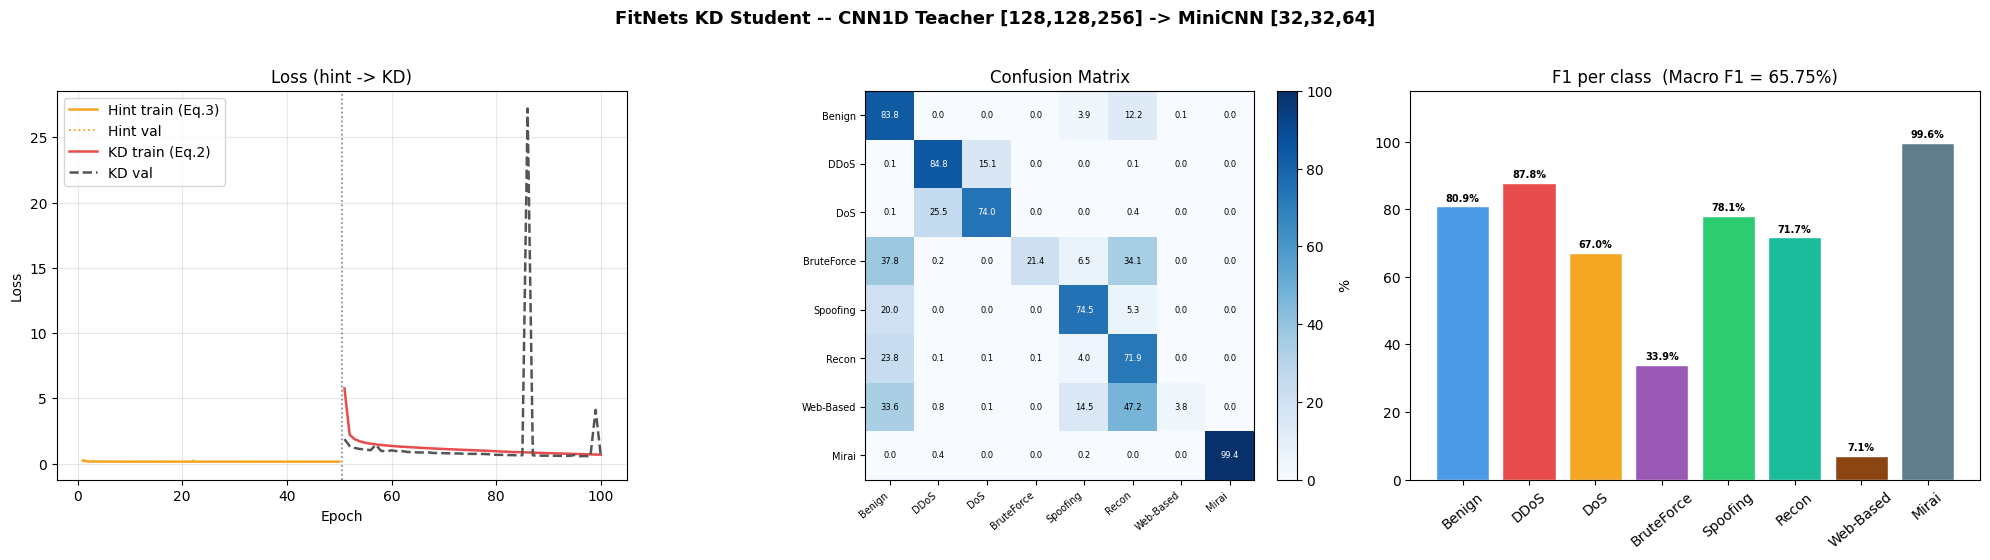

Plot -> /kaggle/working/fitnets_cnn_results.png


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
fig.suptitle('FitNets KD Student -- CNN1D Teacher [128,128,256] -> MiniCNN [32,32,64]',
             fontsize=13, fontweight='bold', y=1.01)

ax = axes[0]
if hint_losses:
    ep_h = range(1, len(hint_losses) + 1)
    ax.plot(ep_h, hint_losses, color='#F5A623', lw=1.8, label='Hint train (Eq.3)')
    if hint_val_losses:
        ax.plot(ep_h, hint_val_losses, color='#F5A623', lw=1.3, ls=':', label='Hint val')
if train_losses:
    ep_k = range(HINT_EPOCHS + 1, HINT_EPOCHS + len(train_losses) + 1)
    ax.plot(ep_k, train_losses, color='#E84C4C', lw=1.8, label='KD train (Eq.2)')
    ax.plot(ep_k, val_losses,   color='#555555', lw=1.8, ls='--', label='KD val')
ax.axvline(HINT_EPOCHS + 0.5, color='gray', ls=':', lw=1.2)
ax.set_title('Loss (hint -> KD)'); ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
cm = confusion_matrix(labels, preds)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
im = ax.imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='%')
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(CLASS_NAMES, rotation=40, ha='right', fontsize=7)
ax.set_yticklabels(CLASS_NAMES, fontsize=7)
ax.set_title('Confusion Matrix')
thresh = cm_pct.max() / 2
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        v = cm_pct[i, j]
        ax.text(j, i, f'{v:.1f}', ha='center', va='center',
                fontsize=6, color='white' if v > thresh else 'black')

ax = axes[2]
f1s = f1_score(labels, preds, average=None, zero_division=0)
bars = ax.bar(CLASS_NAMES, f1s*100, color=COLORS, edgecolor='white')
ax.set_ylim(0, 115)
ax.set_title(f'F1 per class  (Macro F1 = {np.mean(f1s)*100:.2f}%)')
ax.tick_params(axis='x', rotation=40)
for bar, val in zip(bars, f1s):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
            f'{val*100:.1f}%', ha='center', fontsize=7, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.99])
plot_path = os.path.join(OUTPUT_DIR, 'fitnets_cnn_results.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Plot -> {plot_path}')


## Cell 10 — Export config & ONNX

In [11]:
def export_config_onnx(student, acc, macro_auc):
    n_params = count_params(student)
    config = {
        'model'        : 'FitNets-Student-MiniCNN',
        'teacher'      : 'CNN1D-128-128-256',
        'num_features' : NUM_FEATURES,
        'num_classes'  : NUM_CLASSES,
        'teacher_filters': FILTERS_TEACHER,
        'student_filters': FILTERS_STUDENT,
        'distillation' : {
            'method'      : 'FitNets (Romero et al. 2015)',
            'stages'      : {'hint_epochs': HINT_EPOCHS, 'kd_epochs': KD_EPOCHS},
            'hint_block'  : HINT_BLOCK,
            'hint_ch'     : HINT_CH, 'guided_ch': GUIDED_CH,
            'regressor'   : 'Conv1d 1x1',
            'lambda_init' : LAMBDA_INIT, 'lambda_final': LAMBDA_FINAL,
            'tau'         : TAU,
        },
        'performance'  : {
            'accuracy'    : round(float(acc), 6),
            'macro_auc'   : round(float(macro_auc), 6),
            'params'      : n_params,
            'size_mb_fp32': round(n_params*4/1024**2, 4),
            'compression' : round(1 - n_params/t_params, 4),
        },
    }
    cfg_path = os.path.join(OUTPUT_DIR, 'config_fitnets_cnn.json')
    with open(cfg_path, 'w') as f: json.dump(config, f, indent=2)
    print(f'Config -> {cfg_path}')

    student_cpu = student.cpu().eval()
    try:
        onnx_path = os.path.join(OUTPUT_DIR, 'student_cnn_fitnets.onnx')
        torch.onnx.export(
            student_cpu, torch.randn(1, 1, NUM_FEATURES), onnx_path,
            input_names=['features'], output_names=['logits'],
            dynamic_axes={'features':{0:'batch'},'logits':{0:'batch'}},
            opset_version=13,
        )
        sz = os.path.getsize(onnx_path)/1024
        print(f'ONNX  -> {onnx_path}  ({sz:.1f} KB)')
    except Exception as e:
        print(f'  ONNX ERROR: {e}')
    student.to(DEVICE)


export_config_onnx(student, acc, macro_auc)

print('\n' + '='*62)
print('  KET QUA FitNets Student (CNN Teacher)')
print('='*62)
print(f'  {"Accuracy":20s}: {acc*100:.4f}%')
print(f'  {"Macro AUC":20s}: {macro_auc:.6f}')
print(f'  {"Params":20s}: {count_params(student):,}')
print(f'  {"Size (MB)":20s}: {count_params(student)*4/1024**2:.4f}')
print(f'  {"Compression":20s}: {1 - count_params(student)/t_params:.1%}')
print('='*62)
print('\nOutput files:')
for fname in sorted(os.listdir(OUTPUT_DIR)):
    fp = os.path.join(OUTPUT_DIR, fname)
    if os.path.isfile(fp):
        print(f'  {fname:<45} {os.path.getsize(fp)/1024:>8.1f} KB')


Config -> /kaggle/working/config_fitnets_cnn.json
  ONNX ERROR: No module named 'onnxscript'

  KET QUA FitNets Student (CNN Teacher)
  Accuracy            : 82.8724%
  Macro AUC           : 0.972852
  Params              : 11,752
  Size (MB)           : 0.0448
  Compression         : 92.5%

Output files:
  __notebook__.ipynb                               218.5 KB
  config_fitnets_cnn.json                            0.7 KB
  fitnets_cnn_results.png                          171.9 KB
  results_fitnets_cnn.txt                            1.2 KB
  student_cnn_fitnets_classw3_37ft.pth              56.0 KB
  teacher_cnn_converted.pth                        627.7 KB
